Cotações: bid 99.98 | ask 100.02 | spread 0.04
Comprou a 99.98 e vendeu a 100.02: P&L = 4.00 em 100 ações (0.04 por ação)
Inventário: 1000 ações | caixa -99,980
  preço justo 100.00: P&L = 20
  preço justo 99.50: P&L = -480
  preço justo 99.00: P&L = -980
Custo médio: 99.98 | não realizado a 99.50: -480
Vendeu 400 a 99.52: realizado -184 | posição 600 | custo médio 99.98
  inventário     0: bid 99.98 | ask 100.02 | spread 0.04
  inventário  3000: bid 99.89 | ask 99.99 | spread 0.10
  inventário -3000: bid 100.01 | ask 100.11 | spread 0.10
Um dia: P&L 708 = spread 1,749 + inventário -1,040 | inventário final 5,000


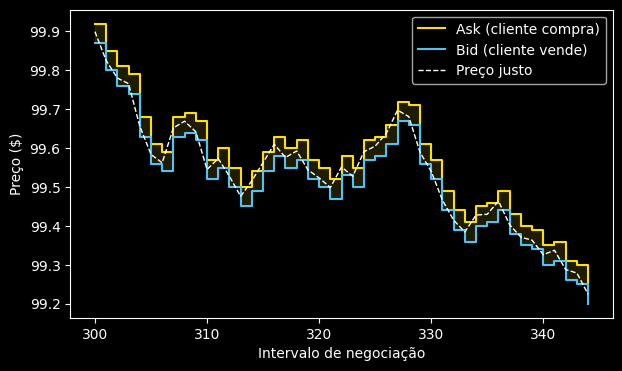

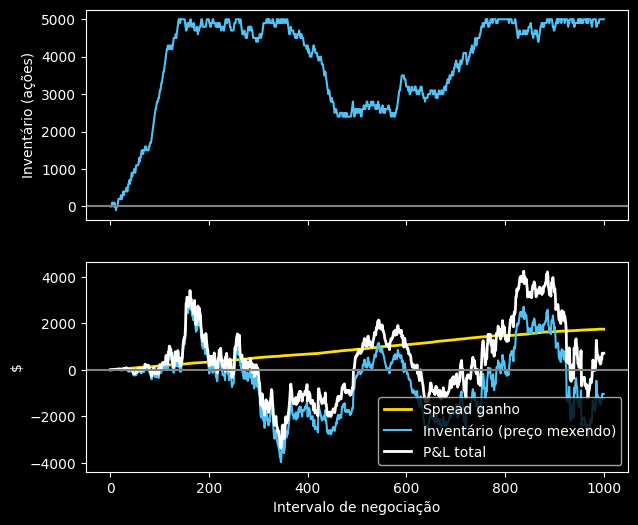

Realizado 1,400 + não realizado -691 = 708 (P&L do passo 6: 708)


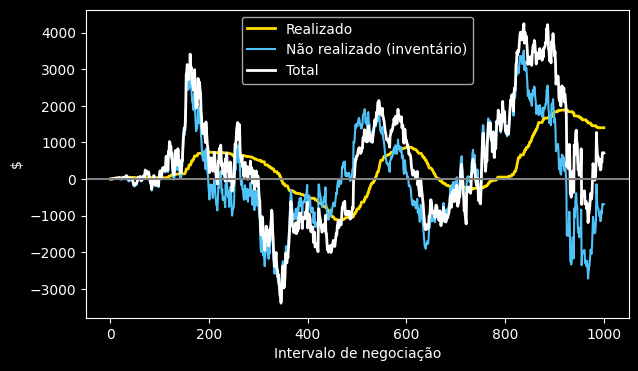

Estratégia                 P&L médio   Desvio   Pior 5%  |Inv.| médio
Cotação fixa                   1,297    5,401    -7,746         2,728
Desloca com o inventário       1,333      897      -183           403
Desloca e abre o spread        1,392      907      -105           413


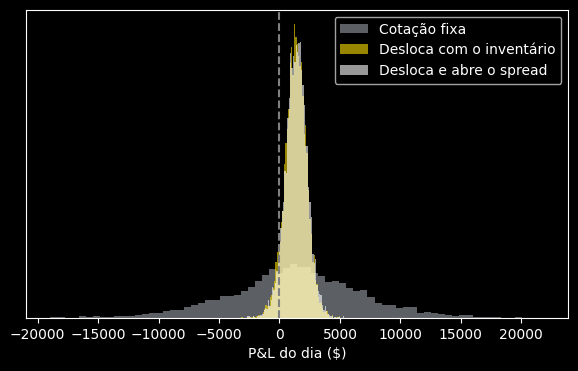

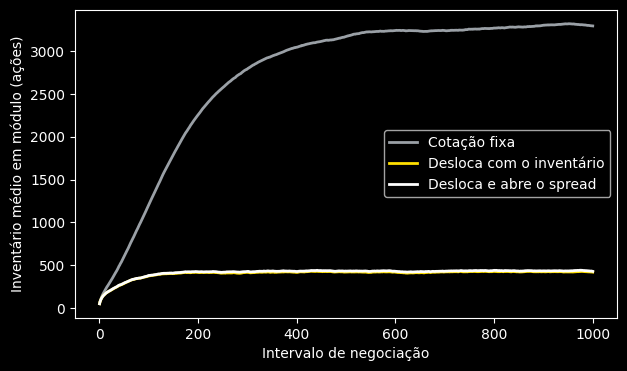

P&L médio, MM que desloca com o inventário (linhas: meio spread; colunas: chance de notícia)
[[ 1418.   961.   490.  -458. -1416.]
 [ 1783.  1353.   903.   -17.  -929.]
 [ 1875.  1466.  1037.   162.  -696.]
 [ 1797.  1414.  1011.   186.  -636.]
 [ 1639.  1278.   885.   105.  -670.]
 [ 1435.  1092.   728.    -9.  -760.]]


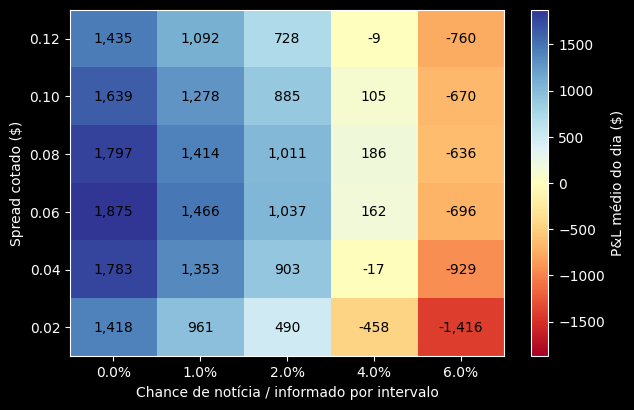

In [1]:
"""Quant Finance: Market Maker (formador de mercado).

Um market maker sempre oferece dois preços: o ask (mais alto, o que você paga
ao comprar) e o bid (mais baixo, o que você recebe ao vender). Quando um
investidor de varejo opera, o outro lado costuma ser um market maker: sempre
tem alguém para negociar. Isso é prover liquidez. Em troca, ele ganha o
spread (spread = ask - bid), repetido o dia todo.

O trabalho tem dois riscos grandes:
  - Inventário: se muita gente vende de uma vez, ele fica com muita ação, e se
    o preço cai ele perde (P&L = caixa + inventário x preço justo).
  - Investidores informados: quem sabe da notícia antes negocia com ele logo
    antes de o preço mexer.
Um bom market maker desloca os dois preços com o inventário e abre o spread
quando o risco cresce. Em várias bolsas, os market makers oficiais prometem
cotar dentro de um spread máximo e pagam taxas menores em troca.

Ideias centrais: ganhar o spread, custo médio e inventário.

Mercado simulado, todos os números assumidos, material educacional. Mostra
como o MÉTODO funciona, não o que um market maker real ganha.

Requer: numpy e matplotlib.
"""
import os

os.makedirs("graficos_market_maker", exist_ok=True)

#Passo 1: parâmetros
import numpy as np

rng = np.random.default_rng(42)
S0 = 100.0               # preço justo inicial
passos = 1000            # intervalos de negociação em um dia
vol_dia = 0.015          # volatilidade do preço justo no dia
sig = S0 * vol_dia / np.sqrt(passos)
tamanho = 100            # ações por ordem de cliente
meia0 = 0.02             # meio spread básico: bid 99.98 e ask 100.02
tick = 0.01              # menor variação de preço
spread_max = 0.20        # obrigação do market maker oficial: spread máximo
A, k = 0.8, 30.0         # chegada de clientes: A * exp(-k * distância ao preço justo)
p_news = 0.01            # chance de notícia (e de um informado) a cada intervalo
salto = 0.25             # tamanho do salto do preço na notícia
tam_inf = 200            # ações da ordem do informado
q_max = 5000             # limite de inventário (ações)
gamma = 2e-5             # deslocamento das cotações por ação de inventário
alfa = 1e-5              # abertura do spread por ação de inventário

#Passo 2: duas cotações e o spread
def cotar(mid, meia):
    """Duas cotações em torno do preço médio, arredondadas ao tick."""
    bid = np.floor(np.round((mid - meia) / tick, 6)) * tick
    ask = np.ceil(np.round((mid + meia) / tick, 6)) * tick
    return np.round(bid, 2), np.round(ask, 2)

def negocio_cliente(caixa, q, lado, bid, ask, n):
    """O cliente compra no ask ou vende no bid. O market maker faz o contrário."""
    if lado == "compra":
        return caixa + ask * n, q - n
    return caixa - bid * n, q + n

def pnl(caixa, q, justo):
    return caixa + q * justo

bid, ask = cotar(100.0, meia0)
print(f"Cotações: bid {bid:.2f} | ask {ask:.2f} | spread {ask - bid:.2f}")
caixa, q = 0.0, 0
caixa, q = negocio_cliente(caixa, q, "venda", bid, ask, 100)    # o MM compra no bid
caixa, q = negocio_cliente(caixa, q, "compra", bid, ask, 100)   # o MM vende no ask
print(f"Comprou a {bid:.2f} e vendeu a {ask:.2f}: P&L = {pnl(caixa, q, 100.0):.2f} "
      f"em 100 ações ({(ask - bid):.2f} por ação)")

#Passo 3: o risco do inventário
caixa, q = 0.0, 0
caixa, q = negocio_cliente(caixa, q, "venda", bid, ask, 1000)   # muita gente vende
print(f"Inventário: {q} ações | caixa {caixa:,.0f}")
for justo in (100.0, 99.5, 99.0):
    print(f"  preço justo {justo:.2f}: P&L = {pnl(caixa, q, justo):,.0f}")

#Passo 4: custo médio, P&L realizado e não realizado
def atualiza(q, custo, preco, n):
    """n > 0: o MM compra; n < 0: vende. Devolve q, custo médio e P&L realizado."""
    novo = q + n
    if q == 0 or np.sign(n) == np.sign(q):          # a posição aumenta
        custo = (q * custo + n * preco) / novo
        return novo, custo, 0.0
    fechado = min(abs(n), abs(q))                   # a posição diminui ou inverte
    realizado = fechado * np.sign(q) * (preco - custo)
    if abs(n) > abs(q):
        custo = preco
    if novo == 0:
        custo = 0.0
    return novo, custo, realizado

q4, custo4, real4 = atualiza(0, 0.0, 99.98, 1000)       # compra 1.000 a 99.98
print(f"Custo médio: {custo4:.2f} | não realizado a 99.50: {q4 * (99.50 - custo4):,.0f}")
q4, custo4, r = atualiza(q4, custo4, 99.52, -400)       # vende 400 a 99.52
real4 += r
print(f"Vendeu 400 a 99.52: realizado {real4:,.0f} | posição {q4} | custo médio {custo4:.2f}")

#Passo 5: cotação deslocada pelo inventário
def cotacao_inventario(mid, q, meia_=meia0, gamma_=gamma, alfa_=alfa):
    """Com muito estoque, as duas cotações descem (para vender) e o spread abre."""
    reserva = mid - gamma_ * q
    meia = np.minimum(meia_ + alfa_ * np.abs(q), spread_max / 2)
    return cotar(reserva, meia)

for inv in (0, 3000, -3000):
    b, a = cotacao_inventario(100.0, inv)
    print(f"  inventário {inv:>5}: bid {b:.2f} | ask {a:.2f} | spread {a - b:.2f}")

#Passo 6: um dia de negociação, simulado
def simula(n, gamma_=0.0, alfa_=0.0, meia_=meia0, p_news_=p_news,
           semente=7, guardar=False, hist_q=False):
    """n dias em paralelo. Mesma semente = mesmos clientes e notícias para cada estratégia."""
    g = np.random.default_rng(semente)
    S = np.full(n, S0)
    q = np.zeros(n)
    caixa = np.zeros(n)
    spread_ac = np.zeros(n)
    mtm = np.zeros(n)
    theta = np.zeros(n)                   # desequilíbrio do fluxo (muita gente vendendo)
    h = {k_: [] for k_ in ("S", "S_fim", "bid", "ask", "q", "vend", "comp", "spread", "mtm", "pnl")}
    qh = []
    for t in range(passos):
        bid, ask = cotacao_inventario(S, q, meia_, gamma_, alfa_)
        pode_vender = q > -q_max
        pode_comprar = q < q_max
        theta = np.clip(0.99 * theta + 0.042 * g.standard_normal(n), -0.9, 0.9)
        p_cc = np.clip(A * np.exp(-k * (ask - S)) * (1 + theta), 0, 1)
        p_cv = np.clip(A * np.exp(-k * (S - bid)) * (1 - theta), 0, 1)
        cc = (g.random(n) < p_cc) & pode_vender          # cliente compra no ask
        cv = (g.random(n) < p_cv) & pode_comprar         # cliente vende no bid
        noticia = g.random(n) < p_news_
        dir_ = np.where(g.random(n) < 0.5, 1, -1)
        inf_c = noticia & (dir_ == 1) & pode_vender      # informado compra antes da alta
        inf_v = noticia & (dir_ == -1) & pode_comprar    # informado vende antes da queda
        vend = cc * tamanho + inf_c * tam_inf            # ações que o MM vende
        comp = cv * tamanho + inf_v * tam_inf            # ações que o MM compra
        caixa += ask * vend - bid * comp
        q += comp - vend
        spread_ac += (ask - S) * vend + (S - bid) * comp
        S_antes = S
        S = S + sig * g.standard_normal(n) + noticia * dir_ * salto
        mtm += q * (S - S_antes)
        if guardar:
            for nome, v in (("S", S_antes), ("S_fim", S), ("bid", bid), ("ask", ask), ("q", q),
                            ("vend", vend), ("comp", comp), ("spread", spread_ac),
                            ("mtm", mtm), ("pnl", caixa + q * S)):
                h[nome].append(v.copy())
        if hist_q:
            qh.append(q.copy())
    assert np.allclose(caixa + q * S, spread_ac + mtm)   # P&L = spread + inventário
    saida = dict(pnl=caixa + q * S, q=q, spread=spread_ac, mtm=mtm)
    if guardar:
        saida["h"] = {k_: np.array(v)[:, 0] for k_, v in h.items()}
    if hist_q:
        saida["qh"] = np.array(qh)
    return saida

dia = simula(1, guardar=True)
h = dia["h"]
print(f"Um dia: P&L {dia['pnl'][0]:,.0f} = spread {dia['spread'][0]:,.0f} "
      f"+ inventário {dia['mtm'][0]:,.0f} | inventário final {dia['q'][0]:,.0f}")

#Gráfico 1: as duas cotações em torno do preço justo
import matplotlib.pyplot as plt
plt.style.use("dark_background")
amarelo = "#FFDF00"
azul = "#4FC3F7"
verde = "#69F0AE"

i0, i1 = 300, 345
x = np.arange(i0, i1)
plt.figure(figsize=(7, 4))
plt.step(x, h["ask"][i0:i1], color=amarelo, where="post", label="Ask (cliente compra)")
plt.step(x, h["bid"][i0:i1], color=azul, where="post", label="Bid (cliente vende)")
plt.plot(x, h["S"][i0:i1], color="white", lw=1, ls="--", label="Preço justo")
plt.fill_between(x, h["bid"][i0:i1], h["ask"][i0:i1], step="post", color=amarelo, alpha=0.12)
plt.xlabel("Intervalo de negociação")
plt.ylabel("Preço ($)")
plt.legend()
plt.savefig("graficos_market_maker/grafico1_cotacoes.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

#Gráfico 2: inventário e de onde vem o P&L
t = np.arange(1, passos + 1)
fig, (a, b) = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
a.plot(t, h["q"], color=azul)
a.axhline(0, color="gray")
a.set_ylabel("Inventário (ações)")
b.plot(t, h["spread"], color=amarelo, lw=2, label="Spread ganho")
b.plot(t, h["mtm"], color=azul, label="Inventário (preço mexendo)")
b.plot(t, h["pnl"], color="white", lw=2, label="P&L total")
b.axhline(0, color="gray")
b.set_xlabel("Intervalo de negociação")
b.set_ylabel("$")
b.legend(loc="lower right")
plt.savefig("graficos_market_maker/grafico2_inventario_pnl.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

#Passo 7: custo médio ao longo do dia
q_, c_, real = 0, 0.0, 0.0
realizado, naoreal, custo_serie = [], [], []
for i in range(passos):
    comp, vend = h["comp"][i], h["vend"][i]
    if comp > 0:
        q_, c_, r = atualiza(q_, c_, h["bid"][i], comp)
        real += r
    if vend > 0:
        q_, c_, r = atualiza(q_, c_, h["ask"][i], -vend)
        real += r
    realizado.append(real)
    naoreal.append(q_ * (h["S_fim"][i] - c_) if q_ != 0 else 0.0)
    custo_serie.append(c_ if q_ != 0 else np.nan)
realizado, naoreal = np.array(realizado), np.array(naoreal)
print(f"Realizado {realizado[-1]:,.0f} + não realizado {naoreal[-1]:,.0f} = "
      f"{realizado[-1] + naoreal[-1]:,.0f} (P&L do passo 6: {h['pnl'][-1]:,.0f})")

#Gráfico 3: P&L realizado e não realizado
plt.figure(figsize=(7, 4))
plt.plot(t, realizado, color=amarelo, lw=2, label="Realizado")
plt.plot(t, naoreal, color=azul, label="Não realizado (inventário)")
plt.plot(t, realizado + naoreal, color="white", lw=2, label="Total")
plt.axhline(0, color="gray")
plt.xlabel("Intervalo de negociação")
plt.ylabel("$")
plt.legend()
plt.savefig("graficos_market_maker/grafico3_realizado.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

#Passo 8: três market makers, 5.000 dias cada
estrategias = {
    "Cotação fixa": dict(gamma_=0.0, alfa_=0.0),
    "Desloca com o inventário": dict(gamma_=gamma, alfa_=0.0),
    "Desloca e abre o spread": dict(gamma_=gamma, alfa_=alfa),
}
res = {nome: simula(5000, hist_q=(True), **par) for nome, par in estrategias.items()}
print(f"{'Estratégia':<26}{'P&L médio':>10}{'Desvio':>9}{'Pior 5%':>10}{'|Inv.| médio':>14}")
for nome, r in res.items():
    p = r["pnl"]
    print(f"{nome:<26}{p.mean():>10,.0f}{p.std():>9,.0f}{np.percentile(p, 5):>10,.0f}"
          f"{np.abs(r['qh']).mean():>14,.0f}")

#Gráfico 4: distribuição do P&L do dia
cores3 = ["#9AA0A6", amarelo, "white"]
plt.figure(figsize=(7, 4))
for (nome, r), cor in zip(res.items(), cores3):
    plt.hist(r["pnl"], bins=70, alpha=0.6, color=cor, label=nome, density=True)
plt.axvline(0, color="gray", ls="--")
plt.xlabel("P&L do dia ($)")
plt.yticks([])
plt.legend()
plt.savefig("graficos_market_maker/grafico4_distribuicao_pnl.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

#Gráfico 5: o inventário, estratégia por estratégia
plt.figure(figsize=(7, 4))
for (nome, r), cor in zip(res.items(), cores3):
    plt.plot(t, np.abs(r["qh"]).mean(axis=1), color=cor, lw=2, label=nome)
plt.xlabel("Intervalo de negociação")
plt.ylabel("Inventário médio em módulo (ações)")
plt.legend()
plt.savefig("graficos_market_maker/grafico5_inventario.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

#Passo 9: quanto cobrar de spread? (spread x notícias)
metas = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06]          # meio spread
noticias = [0.0, 0.01, 0.02, 0.04, 0.06]
grade = np.zeros((len(metas), len(noticias)))
for i, m in enumerate(metas):
    for j, pn in enumerate(noticias):
        grade[i, j] = simula(1000, gamma, 0.0, meia_=m, p_news_=pn)["pnl"].mean()
print("P&L médio, MM que desloca com o inventário (linhas: meio spread; colunas: chance de notícia)")
print(np.round(grade, 0))

#Gráfico 6: o spread que compensa o risco
plt.figure(figsize=(7, 4.5))
lim = np.abs(grade).max()
plt.imshow(grade, cmap="RdYlBu", vmin=-lim, vmax=lim, aspect="auto", origin="lower")
for i in range(len(metas)):
    for j in range(len(noticias)):
        plt.text(j, i, f"{grade[i, j]:,.0f}", ha="center", va="center", color="black")
plt.xticks(range(len(noticias)), [f"{n:.1%}" for n in noticias])
plt.yticks(range(len(metas)), [f"{2 * m:.2f}" for m in metas])
plt.xlabel("Chance de notícia / informado por intervalo")
plt.ylabel("Spread cotado ($)")
plt.colorbar(label="P&L médio do dia ($)")
plt.savefig("graficos_market_maker/grafico6_spread_vs_informados.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()